# Maximizing gain: a Bayesian approach

A product costs $C$ to make. At price $P$ we sell a quantity $Q$, which decreases with the price, and the gain is $U = Q(P-C)$. We have 15 observations of price and quantity sold. Which price maximizes the expected gain, and how sure are we about it?

If the expected quantity is linear in the price, $\mathbb{E}[Q \mid P] = \beta_0-\beta_1P$, the expected gain $(\beta_0-\beta_1P)(P-C)$ is a parabola in $P$, with its maximum at
$$P^\star = \frac{\beta_0+\beta_1C}{2\beta_1}.$$
With a Bayesian model we get the whole posterior distribution of the optimal price $P^\star$, of the quantity $Q^\star$ we would sell at that price, and of the gain $U^\star$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az

from scipy.stats import norm

In [2]:
ALPHA = 0.25 # Confidence level
SEED = 111   # For reproducible results

In [3]:
def muQ(beta0, beta1, price):
    return(beta0-beta1*price)

def muU(beta0, beta1, price, cost):
    return(beta0-beta1*price)*(price-cost)

## The data

In [4]:
# Data
P = np.array([21, 19, 20, 15, 18, 18, 7, 16, 14, 9, 11, 13, 10, 10, 10])
Q = np.array([3, 3, 7, 6, 10, 15, 16, 13, 9, 15, 9, 15, 12, 18, 21])
C = 3
U = Q*(P-C)

In [5]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
ci_color    = '#7fb8d8'
pi_color    = '#cfe8f3'
opt_color   = '#E69F00'

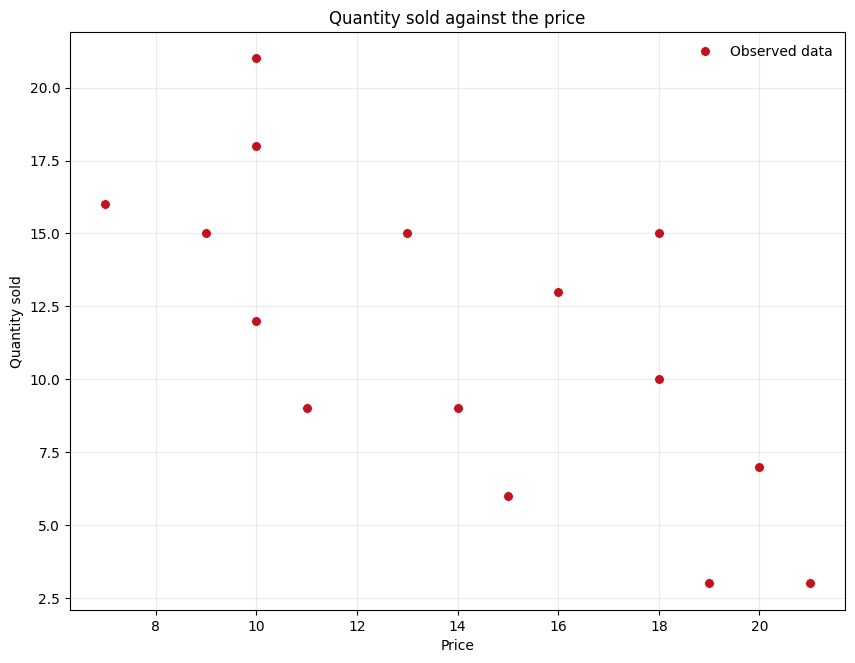

In [6]:
plt.figure(figsize=(10,7.5))
plt.plot(P, Q, 'o', color=point_color, markersize=7, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')

plt.xlabel('Price')
plt.ylabel('Quantity sold')
plt.title('Quantity sold against the price')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)

## The model

$$
\begin{align*}
p(\beta_0) &\propto 1 \\
p(\beta_1) &\propto 1 \\
p(\sigma) &\propto 1 \\
Q &\sim \textsf{Normal}(\beta_0-\beta_1P,\sigma^2) \\\\
\varepsilon &\sim \textsf{Normal}(0,\sigma^2) \\\\
P^\star &= \frac{\beta_0+\beta_1C}{2\beta_1} \\\\
Q^\star &= \beta_0-\beta_1 P^\star+\varepsilon \\\\
U^\star &= Q^\star(P^\star-C)
\end{align*}
$$

In [7]:
with pm.Model() as BayesianModel:
    beta0 = pm.HalfFlat("beta0")
    beta1 = pm.HalfFlat("beta1")
    sigma = pm.HalfFlat("sigma")
    Quantity = pm.Normal("Quantity", beta0-beta1*P, sigma, observed=Q)

    epsilon = pm.Normal("epsilon", 0, sigma)
    PStar = pm.Deterministic("PStar", (beta0+beta1*C)/(2*beta1))
    QStar = pm.Deterministic("QStar", beta0-beta1*PStar+epsilon)
    UStar = pm.Deterministic("UStar", QStar*(PStar-C))

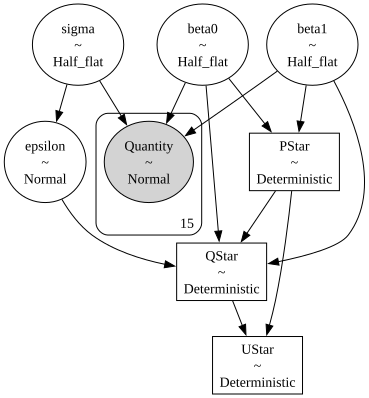

In [8]:
# model_to_graphviz evaluates the shapes of the variables with a mode
# that fails with flat priors in this version of pymc (5.26)
import pymc.model_graph
from pytensor.compile.mode import Mode
pymc.model_graph._cheap_eval_mode = Mode(linker="py", optimizer="fast_compile")

pm.model_to_graphviz(BayesianModel)

In [9]:
with BayesianModel:
    trace = pm.sample(target_accept=0.95, random_seed=SEED)

Initializing NUTS using jitter+adapt_diag...


C:\Users\Dmitri\AppData\Local\Programs\Python\Python311\Lib\site-packages\pytensor\link\c\cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [beta0, beta1, sigma, epsilon]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 36 seconds.


## Posterior summaries

In [10]:
Summary = az.summary(trace, stat_focus="median", hdi_prob=1-ALPHA)
Summary_eti = Summary[Summary.columns[Summary.columns.str.startswith("eti")]]
Summary_median = Summary["median"]

price_vec = np.linspace(6, 22, 50)

Summary

,median,mad,eti_12.5%,eti_87.5%,mcse_median,ess_median,ess_tail,r_hat
epsilon,0.221,2.880,-4.813,5.190,0.098,2829.554,2192.0,1.0
beta0,23.458,2.501,18.964,27.792,0.104,1908.706,936.0,1.0
beta1,0.851,0.170,0.549,1.146,0.007,1817.884,968.0,1.0
sigma,4.226,0.576,3.390,5.489,0.026,1891.044,2017.0,1.0
PStar,15.246,1.393,13.415,19.154,0.052,2190.205,1142.0,1.0
QStar,10.583,3.036,5.480,15.947,0.106,2537.078,2223.0,1.0
UStar,132.351,38.339,70.347,200.426,1.032,3037.533,2255.0,1.0


Confidence and prediction intervals for $Q$

In [11]:
ConfidenceIntervalsQ = pd.DataFrame(
    np.quantile(muQ(trace.posterior["beta0"], trace.posterior["beta1"], price_vec[0]), [ALPHA/2, 1-ALPHA/2]).reshape(1,2),
    columns=['LCI', 'UCI']
)

for i in range(1, len(price_vec)):
    ConfidenceIntervalsQ = pd.concat(
        [ConfidenceIntervalsQ,
         pd.DataFrame(
            np.quantile(muQ(trace.posterior["beta0"], trace.posterior["beta1"], price_vec[i]), [ALPHA/2, 1-ALPHA/2]).reshape(1,2),
            columns=['LCI', 'UCI'])
        ]
    )

ConfidenceIntervalsQ['Price'] = price_vec

In [12]:
rng = np.random.default_rng(SEED)

Q_samp = norm.rvs(
    size=(4,1000),
    loc=muQ(trace.posterior["beta0"], trace.posterior["beta1"], price_vec[0]),
    scale=trace.posterior["sigma"],
    random_state=rng)

PredictionIntervalsQ = pd.DataFrame(np.quantile(Q_samp, [ALPHA/2, 1-ALPHA/2]).reshape(1,2), columns=['LPI', 'UPI'])

for i in range(1, len(price_vec)):
    Q_samp = norm.rvs(
        size=(4,1000),
        loc=muQ(trace.posterior["beta0"], trace.posterior["beta1"], price_vec[i]),
        scale=trace.posterior["sigma"],
        random_state=rng)

    PredictionIntervalsQ = pd.concat(
        [PredictionIntervalsQ, pd.DataFrame(np.quantile(Q_samp, [ALPHA/2, 1-ALPHA/2]).reshape(1,2), columns=['LPI', 'UPI'])])

PredictionIntervalsQ['Price'] = price_vec

Confidence and prediction intervals for $U$

In [13]:
ConfidenceIntervalsU = pd.DataFrame(
    np.quantile(muU(trace.posterior["beta0"], trace.posterior["beta1"], price_vec[0], C), [ALPHA/2, 1-ALPHA/2]).reshape(1,2),
    columns=['LCI', 'UCI']
)

for i in range(1, len(price_vec)):
    ConfidenceIntervalsU = pd.concat(
        [ConfidenceIntervalsU,
         pd.DataFrame(
            np.quantile(muU(trace.posterior["beta0"], trace.posterior["beta1"], price_vec[i], C), [ALPHA/2, 1-ALPHA/2]).reshape(1,2),
            columns=['LCI', 'UCI'])
        ]
    )

ConfidenceIntervalsU['Price'] = price_vec

In [14]:
U_samp = norm.rvs(
    size=(4,1000),
    loc=muU(trace.posterior["beta0"], trace.posterior["beta1"], price_vec[0], C),
    scale=(price_vec[0]-C)*trace.posterior["sigma"],
    random_state=rng)

PredictionIntervalsU = pd.DataFrame(np.quantile(U_samp, [ALPHA/2, 1-ALPHA/2]).reshape(1,2), columns=['LPI', 'UPI'])

for i in range(1, len(price_vec)):
    U_samp = norm.rvs(
        size=(4,1000),
        loc=muU(trace.posterior["beta0"], trace.posterior["beta1"], price_vec[i], C),
        scale=(price_vec[i]-C)*trace.posterior["sigma"],
        random_state=rng)

    PredictionIntervalsU = pd.concat(
        [PredictionIntervalsU, pd.DataFrame(np.quantile(U_samp, [ALPHA/2, 1-ALPHA/2]).reshape(1,2), columns=['LPI', 'UPI'])])

PredictionIntervalsU['Price'] = price_vec

## The optimum

Posterior distributions of the optimal price, and of the quantity and the gain at that price.

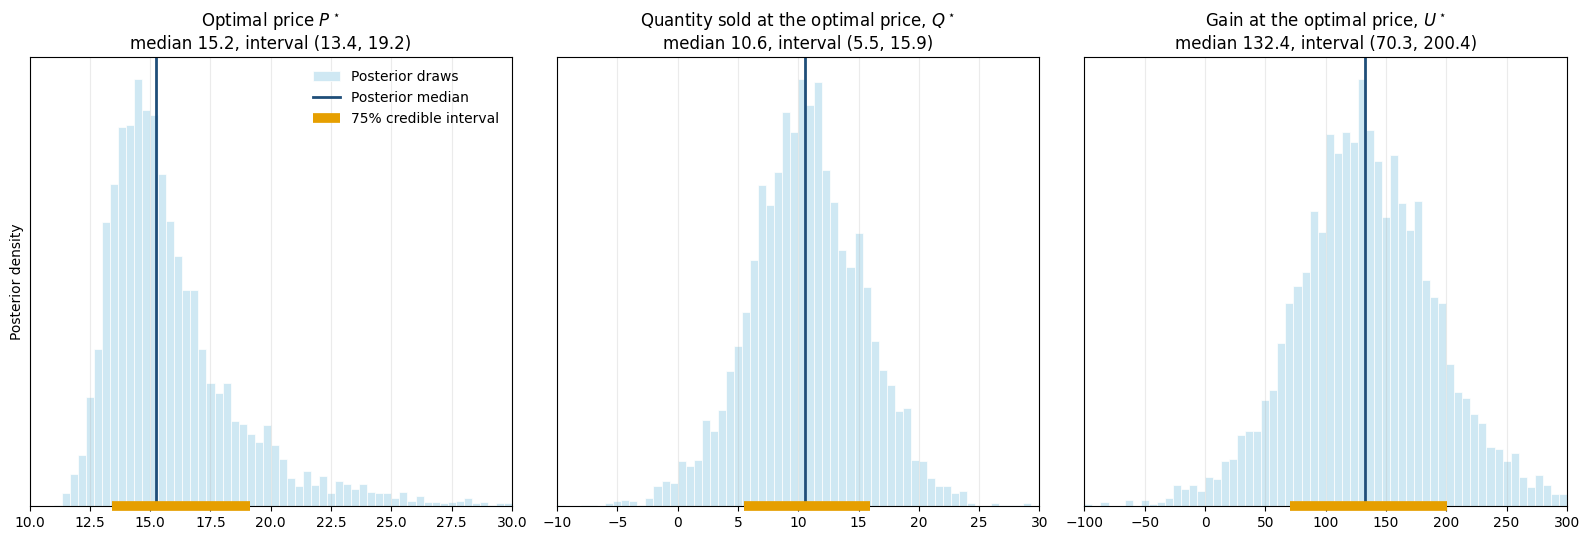

In [15]:
panels = [("PStar", r"Optimal price $P^\star$", (10, 30)),
          ("QStar", r"Quantity sold at the optimal price, $Q^\star$", (-10, 30)),
          ("UStar", r"Gain at the optimal price, $U^\star$", (-100, 300))]
interval_label = f'{(1 - ALPHA) * 100:.0f}% credible interval'

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, (variable, title, limits) in zip(axes, panels):
    draws = trace.posterior[variable].to_numpy().ravel()
    # The posterior of the optimum has long tails, we show the central part
    ax.hist(draws, bins=np.linspace(limits[0], limits[1], 61), density=True, color=pi_color, edgecolor='white',
            linewidth=0.5, label='Posterior draws')
    ax.axvline(Summary_median[variable], color=line_color, lw=2, label='Posterior median')
    ax.plot(Summary_eti.loc[variable], [0, 0], color=opt_color, lw=7, solid_capstyle='butt', clip_on=False, zorder=5,
            label=interval_label)
    low, upp = Summary_eti.loc[variable]
    ax.set_title(f'{title}\nmedian {Summary_median[variable]:.1f}, interval ({low:.1f}, {upp:.1f})')
    ax.set_xlim(limits)
    ax.set_yticks([])
    ax.grid(True, axis='x', alpha=0.25)
axes[0].set_ylabel('Posterior density')
axes[0].legend(loc='upper right', frameon=False)
plt.tight_layout()

## Price and quantity

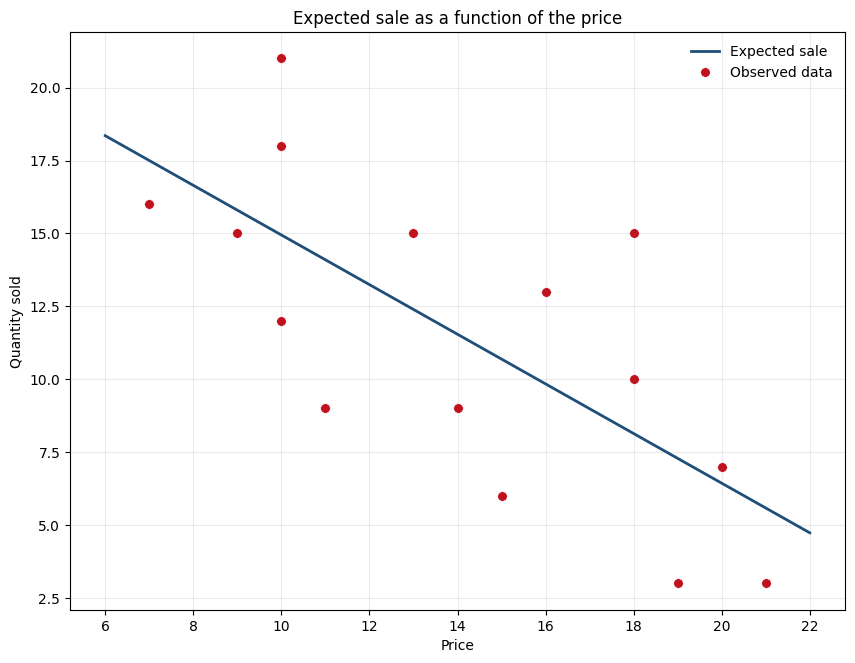

In [16]:
plt.figure(figsize=(10,7.5))

# Fitted curve as a line, not markers — it's a model, not observations
plt.plot(price_vec, muQ(Summary_median["beta0"], Summary_median["beta1"], price_vec), color=line_color, lw=2, label='Expected sale')

# Observed data on top, dark and distinct
plt.plot(P, Q, 'o', color=point_color, markersize=7, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')

plt.xlabel('Price')
plt.ylabel('Quantity sold')
plt.title('Expected sale as a function of the price')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)

In [17]:
def plot_optimum(ax, variable):
    # Optimal price with its interval, on the horizontal axis and on the curve
    bottom = ax.get_ylim()[0]
    label = f'Optimum, with {(1 - ALPHA) * 100:.0f}% intervals'
    ax.plot([Summary_median["PStar"], Summary_median["PStar"]], Summary_eti.loc[variable], color=opt_color, lw=3)
    ax.plot(Summary_median["PStar"], Summary_median[variable], 'o', color=opt_color, markersize=11,
            markeredgecolor='#333333', markeredgewidth=1.2, label=label, zorder=5)
    ax.plot(Summary_eti.loc["PStar"], [bottom, bottom], color=opt_color, lw=6, solid_capstyle='butt', clip_on=False, zorder=5)
    ax.plot(Summary_median["PStar"], bottom, 'o', color=opt_color, markersize=11, markeredgecolor='#333333',
            markeredgewidth=1.2, clip_on=False, zorder=6)
    ax.vlines(Summary_median["PStar"], bottom, Summary_median[variable], color=opt_color, lw=1, ls=':')
    ax.set_ylim(bottom, None)

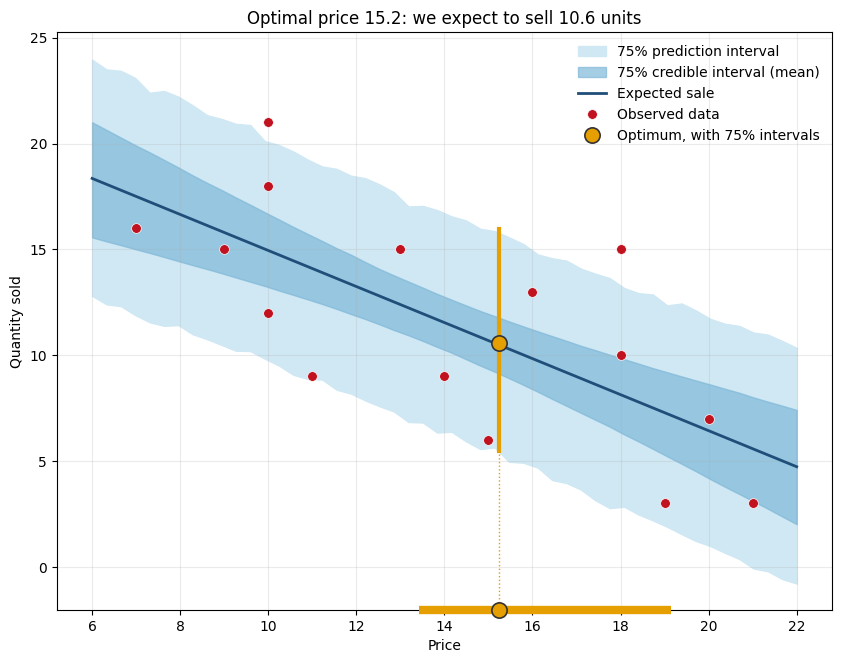

In [18]:
fig, ax = plt.subplots(figsize=(10,7.5))

# Bands: light, low-saturation fills, ordered wide-to-narrow
ci_label = f'{(1 - ALPHA) * 100:.0f}% credible interval (mean)'
pi_label = f'{(1 - ALPHA) * 100:.0f}% prediction interval'
ax.fill_between(price_vec, PredictionIntervalsQ['LPI'], PredictionIntervalsQ['UPI'], color=pi_color, label=pi_label)
ax.fill_between(price_vec, ConfidenceIntervalsQ['LCI'], ConfidenceIntervalsQ['UCI'], color=ci_color, alpha=0.7, label=ci_label)

ax.plot(price_vec, muQ(Summary_median["beta0"], Summary_median["beta1"], price_vec), color=line_color, lw=2, label='Expected sale')
ax.plot(P, Q, 'o', color=point_color, markersize=7, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')

plot_optimum(ax, "QStar")

ax.set_xlabel('Price')
ax.set_ylabel('Quantity sold')
ax.set_title(f'Optimal price {Summary_median["PStar"]:.1f}: we expect to sell {Summary_median["QStar"]:.1f} units')
ax.legend(loc='upper right', frameon=False)
ax.grid(True, alpha=0.25)

## Price and gain

The expected gain is a parabola in the price, the optimal price is where it has its maximum. The curve is quite flat around the optimum: prices a little lower or higher give almost the same expected gain, which is why the interval for $P^\star$ is wide.

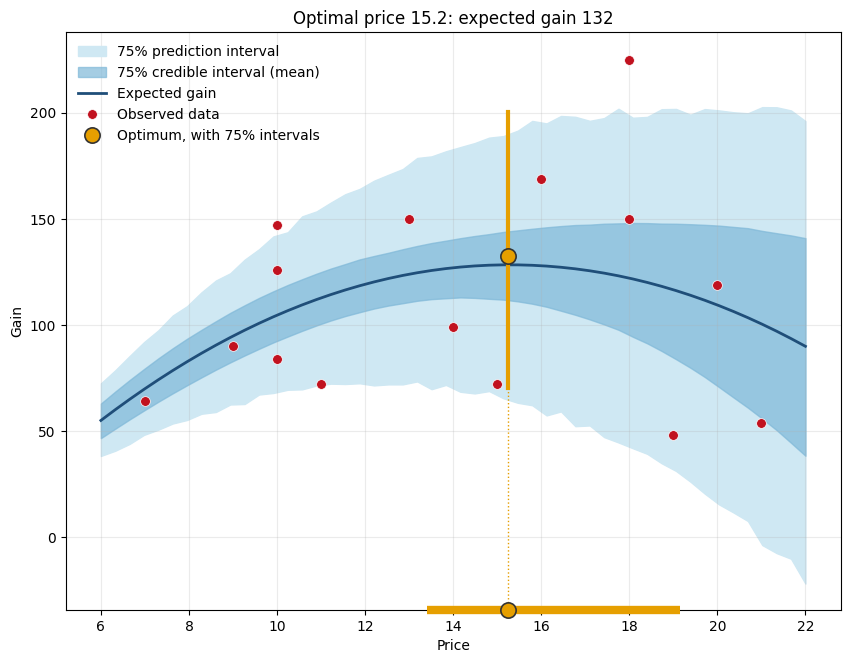

In [19]:
fig, ax = plt.subplots(figsize=(10,7.5))

ax.fill_between(price_vec, PredictionIntervalsU['LPI'], PredictionIntervalsU['UPI'], color=pi_color, label=pi_label)
ax.fill_between(price_vec, ConfidenceIntervalsU['LCI'], ConfidenceIntervalsU['UCI'], color=ci_color, alpha=0.7, label=ci_label)

ax.plot(price_vec, muU(Summary_median["beta0"], Summary_median["beta1"], price_vec, C), color=line_color, lw=2, label='Expected gain')
ax.plot(P, U, 'o', color=point_color, markersize=7, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')

plot_optimum(ax, "UStar")

ax.set_xlabel('Price')
ax.set_ylabel('Gain')
ax.set_title(f'Optimal price {Summary_median["PStar"]:.1f}: expected gain {Summary_median["UStar"]:.0f}')
ax.legend(loc='upper left', frameon=False)
ax.grid(True, alpha=0.25)